# Proyecto 3: análisis de sentimientos en tweets en español con BETO

**Objetivo:** ajustar un modelo BERT preentrenado para clasificar tweets en negativo, neutro o positivo,
comparar tres tasas de aprendizaje y evaluar el mejor modelo sobre datos de prueba reservados.

El proyecto utiliza ejemplos etiquetados en español para adaptar BETO a una tarea de clasificación
de secuencias. El desarrollo comprende la descripción y exploración de los datos, la tokenización,
el fine-tuning, la comparación de hiperparámetros y la evaluación final.


In [1]:
%pip -q install "transformers==4.57.1" "datasets==4.3.0" "accelerate==1.11.0" "torch>=2.6" pandas matplotlib scikit-learn


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2025.9.0 which is incompatible.


## 1. Descripción de la base de datos

Usamos la partición `spanish` de [Tweet Sentiment Multilingual, de Cardiff NLP](https://huggingface.co/datasets/cardiffnlp/tweet_sentiment_multilingual).
El conjunto multilingüe reúne tweets etiquetados en ocho idiomas; este proyecto se limita al español.
Su publicación de referencia es [Barbieri, Espinosa-Anke y Camacho-Collados (2022)](https://aclanthology.org/2022.lrec-1.27/).

| Elemento | Descripción |
|---|---|
| Dominio | Textos y opiniones publicados en Twitter |
| Utilidad | Apoyar el análisis agregado de opiniones sobre servicios, productos o temas de conversación |
| Entrada | `text`: texto de un tweet en español |
| Salida | `label`: 0 = negativo, 1 = neutro, 2 = positivo |
| Tipo de problema | Aprendizaje supervisado; clasificación multiclase de secuencias (*sequence classification*) |
| Unidad de observación | Un tweet, con una única etiqueta |
| Particiones | Entrenamiento para ajustar pesos; validación para elegir configuración; prueba para evaluación final |

Los archivos JSONL descargados contienen **1.839 / 324 / 870 registros**, respectivamente: **3.033 en total**.
La ficha anuncia 1.838 / 323 / 869. Reportamos lo observado en los archivos y fijamos su revisión para reproducirlo.
Las etiquetas originales son cadenas y se convierten a enteros tras validarlas.

La ficha indica CC BY 3.0 y condiciones de Twitter; se conserva la atribución y se enlaza el origen.
No se redistribuye la base completa en este repositorio. El lenguaje informal, el sarcasmo, el contexto ausente
y las variantes regionales pueden dificultar la clasificación. El sentimiento no es un diagnóstico del estado
emocional de una persona y el desempeño en este conjunto no garantiza el mismo desempeño en otras plataformas.

### Por qué elegimos estos datos

El problema tiene una aplicación fácil de entender: una organización puede recibir muchas opiniones y
necesitar un resumen de su tono. Además, el conjunto está en español, tiene un tamaño manejable y ya trae
las tres particiones. Eso nos permite concentrarnos en el fine-tuning y comparar configuraciones.
No son necesariamente opiniones sobre una empresa concreta: ese es un posible uso, no una descripción
de todos los tweets del dataset.


**Para qué sirven las particiones:** entrenamiento es el material con el que el modelo aprende;
validación permite escoger la configuración; prueba es el examen final. Si escogiéramos la configuración
mirando ese examen, dejaría de ser una evaluación independiente de esa elección.


In [2]:
import json
import urllib.request
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 42
ID2LABEL = {0: "negativo", 1: "neutro", 2: "positivo"}
LABEL2ID = {nombre: indice for indice, nombre in ID2LABEL.items()}
DATASET_ID = "cardiffnlp/tweet_sentiment_multilingual"
DATA_REVISION = "14b13edfbc4046892f6011d114c29c0f83170589"
ARTIFACTS = Path("resultados_tweets")
ARTIFACTS.mkdir(exist_ok=True)
plt.rcParams.update({"figure.figsize": (8, 4), "figure.dpi": 110})

frames = {}
for split in ("train", "validation", "test"):
    url = (f"https://huggingface.co/datasets/{DATASET_ID}/resolve/"
           f"{DATA_REVISION}/data/spanish/{split}.jsonl")
    with urllib.request.urlopen(url, timeout=60) as response:
        records = [json.loads(line) for line in response.read().decode("utf-8").splitlines() if line.strip()]
    assert records, f"Partición vacía: {split}"
    assert all(isinstance(r.get("text"), str) and r["text"].strip() for r in records)
    assert all(str(r.get("label")) in {"0", "1", "2"} for r in records)
    frame = pd.DataFrame(records)[["text", "label"]]
    frame["label"] = frame["label"].astype(int)
    frames[split] = frame

sizes = pd.DataFrame({"particion": frames.keys(), "registros": [len(f) for f in frames.values()]})
assert sizes["registros"].tolist() == [1839, 324, 870], "Cambió el contenido esperado; revisa la fuente."
display(sizes)
print("Total de tweets:", sum(len(f) for f in frames.values()))


,particion,registros
0,train,1839
1,validation,324
2,test,870


Total de tweets: 3033


## 2. Calidad y análisis exploratorio

Se comprueban valores vacíos, duplicados exactos y coincidencias de texto entre particiones.
Los controles son estructurales: no usamos las predicciones ni los errores de prueba para tomar decisiones.
La exploración detallada de ejemplos, longitudes y palabras se hace **únicamente con entrenamiento**.
No eliminamos acentos, emojis ni negaciones: pueden aportar información al sentimiento.

### Qué buscamos en la exploración

Contamos las clases para saber si una aparece mucho más que las demás. Mostramos tres tweets de cada
sentimiento para entender qué debe distinguir el modelo. Medimos caracteres y palabras para conocer la
longitud de los textos. Revisamos duplicados para detectar coincidencias exactas que podrían hacer que
una evaluación pareciera más fácil de lo que realmente es.


,particion,nulos,textos_vacios,textos_duplicados
0,train,0,0,0
1,validation,0,0,0
2,test,0,0,0


,particiones,textos_compartidos
0,train / validation,0
1,train / test,0
2,validation / test,0


,train,validation,test
sentimiento,,,
negativo,613,108,290
neutro,613,108,290
positivo,613,108,290


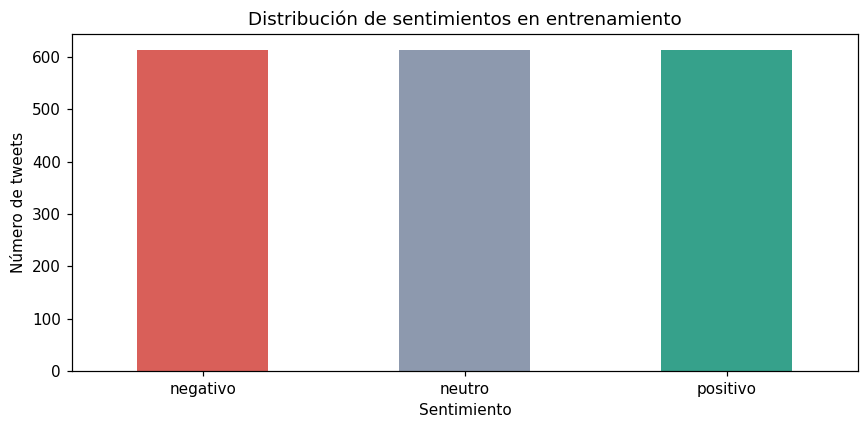

In [3]:
quality = pd.DataFrame([
    {"particion": split, "nulos": int(df.isna().sum().sum()),
     "textos_vacios": int(df["text"].str.strip().eq("").sum()),
     "textos_duplicados": int(df["text"].duplicated().sum())}
    for split, df in frames.items()
])
display(quality)
overlaps = []
for left, right in combinations(frames, 2):
    count = len(set(frames[left]["text"]) & set(frames[right]["text"]))
    overlaps.append({"particiones": f"{left} / {right}", "textos_compartidos": count})
display(pd.DataFrame(overlaps))
assert quality[["nulos", "textos_vacios", "textos_duplicados"]].to_numpy().sum() == 0
assert all(row["textos_compartidos"] == 0 for row in overlaps)

counts = pd.DataFrame({
    split: df["label"].value_counts().reindex(range(3), fill_value=0)
    for split, df in frames.items()
}).rename(index=ID2LABEL)
counts.index.name = "sentimiento"
display(counts)
counts.to_csv(ARTIFACTS / "distribucion_clases.csv")

counts["train"].plot.bar(color=["#d95f59", "#8d99ae", "#36a18b"], rot=0)
plt.title("Distribución de sentimientos en entrenamiento")
plt.xlabel("Sentimiento")
plt.ylabel("Número de tweets")
plt.tight_layout()
plt.savefig(ARTIFACTS / "distribucion_clases.png")
plt.show()


,text,sentimiento
1110,@user estar un poco poseída nada más,negativo
303,@user ni tu como soportas el calor sevillano hija mía,negativo
393,@user Jajaja Y al séptimo día descansó (?) Que mal mae Lo siento,negativo
1111,@user Sería un puntazo que te dieran los domingos de descanso o que trabajases de mañana y así tener la tarde libre para verlo,neutro
304,El viernes dejo de ver a muchas personas por un buen tiempo y ah la,neutro
394,"@user los palitos no son bonitos, los puntos sí #sutileza",neutro
1112,@user Que linda y grande que está Holly,positivo
305,"Buen partido a todos @user , suerte en la final de losers y a ver si nos volvemos a ver en la gran final. Saludo a esos casters",positivo
395,Cada vez que veo a esa muchacha está más guapa,positivo


caracteres                 palabras               
                  mean median min  max     mean median min max
sentimiento                                                   
negativo         85.28   88.0  19  138    16.24   17.0   5  31
neutro           82.30   83.0  22  137    15.39   15.0   5  30
positivo         82.59   81.0  19  138    14.90   14.0   5  30

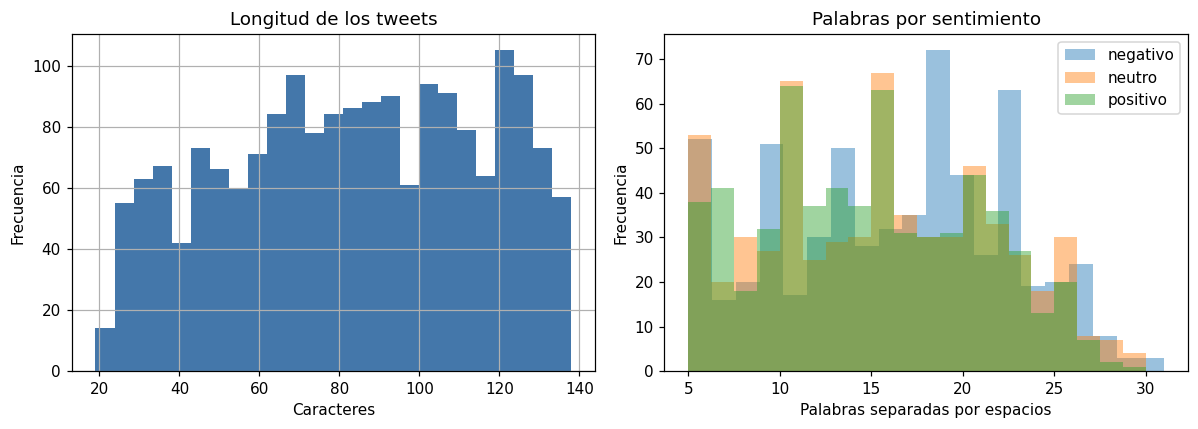

In [4]:
train_df = frames["train"].copy()
train_df["sentimiento"] = train_df["label"].map(ID2LABEL)
examples = pd.concat([
    train_df[train_df["label"] == label].sample(3, random_state=SEED)
    for label in range(3)
])
with pd.option_context("display.max_colwidth", None):
    display(examples[["text", "sentimiento"]])

train_df["caracteres"] = train_df["text"].str.len()
train_df["palabras"] = train_df["text"].str.split().str.len()
display(train_df.groupby("sentimiento")[["caracteres", "palabras"]].agg(["mean", "median", "min", "max"]).round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
train_df["caracteres"].hist(bins=25, ax=axes[0], color="#4477aa")
axes[0].set(title="Longitud de los tweets", xlabel="Caracteres", ylabel="Frecuencia")
for label, group in train_df.groupby("sentimiento"):
    axes[1].hist(group["palabras"], bins=20, alpha=0.45, label=label)
axes[1].set(title="Palabras por sentimiento", xlabel="Palabras separadas por espacios", ylabel="Frecuencia")
axes[1].legend()
plt.tight_layout()
plt.savefig(ARTIFACTS / "longitudes.png")
plt.show()


### Interpretación inicial

Las clases están exactamente balanceadas en cada partición: entrenamiento tiene **613 tweets por clase**,
validación **108** y prueba **290**. No se encontraron textos vacíos, duplicados exactos dentro de las
particiones ni textos idénticos compartidos entre ellas. Esto no descarta duplicados semánticos.
Los textos de entrenamiento tienen entre **19 y 138 caracteres**.

No necesitamos balancear mediante sobremuestreo por frecuencia de clases. Aun así, usaremos **F1 macro**
para dar el mismo peso a los tres sentimientos y revisar diferencias entre ellos. Los ejemplos mostrados
permiten discutir ambigüedad, informalidad y dependencia del contexto; las etiquetas son las de la fuente,
no una garantía de interpretación única.

## 3. Modelo y preparación

[BETO](https://huggingface.co/dccuchile/bert-base-spanish-wwm-cased) es un BERT preentrenado en español.
La variante `cased` distingue mayúsculas. Se incorpora una capa de clasificación con tres salidas y se ajustan
**todos los pesos** mediante aprendizaje supervisado. La capa de clasificación comienza con pesos nuevos;
por eso un aviso de pesos recién inicializados al cargar el modelo es esperado.

Se emplea su propio tokenizador, longitud máxima de 128 tokens y padding dinámico por lote. La proporción
truncada se calcula sobre entrenamiento. Las palabras separadas por espacios del EDA no equivalen a tokens BERT.

### Preparación del texto

El modelo trabaja con números. El **tokenizador** separa el texto en tokens, que pueden ser palabras,
partes de palabras o signos, y los convierte en identificadores numéricos. También agrega tokens especiales.
El **padding** completa los textos más cortos de cada lote para poder procesarlos juntos; la máscara de
atención indica qué posiciones son texto y cuáles son relleno. El **truncamiento** corta secuencias que
superen 128 tokens, incluidos los especiales. La celda informa cuántos tweets de entrenamiento se ven afectados.

**Por qué conservamos el texto:** en «no me gustó», quitar «no» cambiaría el sentimiento. Las mayúsculas,
los signos y los emojis también pueden aportar pistas. Por eso usamos el tokenizador de BETO y conservamos
la información original, en lugar de hacer una limpieza agresiva.

### Qué significa hacer fine-tuning de BETO

BETO ya aprendió patrones del español durante su preentrenamiento. Eso no significa que su modelo base
ya entregue nuestras tres etiquetas: agregamos una capa de clasificación y entrenamos con tweets etiquetados.
En cada lote, el modelo predice, calcula una pérdida comparando con las etiquetas y el optimizador ajusta
sus pesos para reducirla. Esa adaptación a nuestra tarea es el fine-tuning.

En este notebook **la base BERT y la capa de clasificación se ajustan juntas desde el inicio**.


In [5]:
import gc
import time
import platform
import importlib.metadata
import torch
from datasets import Dataset, DatasetDict
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding,
    TrainingArguments, Trainer, set_seed,
)
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from sklearn.dummy import DummyClassifier

if not torch.cuda.is_available():
    raise RuntimeError("Activa una GPU en Colab y vuelve a ejecutar las celdas en orden.")
print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__)
set_seed(SEED)

MODEL_ID = "dccuchile/bert-base-spanish-wwm-cased"
MODEL_REVISION = "c4d86612f51b4f46759c8390d1798c2febe71b93"
MAX_LENGTH = 128
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=MODEL_REVISION)

token_lengths = [len(ids) for ids in tokenizer(frames["train"]["text"].tolist(), truncation=False)["input_ids"]]
print(f"Tweets de entrenamiento que se truncarán: {np.mean(np.array(token_lengths) > MAX_LENGTH):.2%}")

dataset = DatasetDict({split: Dataset.from_pandas(df, preserve_index=False) for split, df in frames.items()})
def tokenize(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)

tokenized = dataset.map(tokenize, batched=True, remove_columns=["text"])
collator = DataCollatorWithPadding(tokenizer=tokenizer)
print(tokenized)

def compute_metrics(eval_prediction):
    logits, labels = eval_prediction
    predictions = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, predictions),
        "f1_macro": f1_score(labels, predictions, labels=[0, 1, 2], average="macro", zero_division=0),
    }

# Comprobación mínima del cálculo de métricas.
perfect = compute_metrics((np.eye(3), np.array([0, 1, 2])))
assert perfect == {"accuracy": 1.0, "f1_macro": 1.0}


GPU: Tesla T4
PyTorch: 2.11.0+cu130


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/364 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/648 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

... (2 outputs left out)

Map:   0%|          | 0/1839 [00:00<?, ? examples/s]

Map:   0%|          | 0/324 [00:00<?, ? examples/s]

Map:   0%|          | 0/870 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 1839
    })
    validation: Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 324
    })
    test: Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 870
    })
})


## 4. Referencia sencilla y diseño experimental

Como referencia usamos un clasificador que siempre predice la clase más frecuente en entrenamiento.
Las frecuencias están empatadas: `DummyClassifier` resuelve el empate de forma determinista.
Este modelo ayuda a comprobar que BETO aprende más que una regla constante; no sustituye el fine-tuning requerido.

| Hiperparámetro | Valores |
|---|---|
| Learning rate | 0,00002; 0,00003; 0,00005 |
| Épocas máximas por experimento | 3 |
| Batch de entrenamiento | 8 |
| Acumulación de gradientes | 2 (batch efectivo de 16 en una GPU) |
| Weight decay | 0,01 |
| Warmup | 10 % de los pasos |
| Longitud máxima | 128 tokens |
| Semilla | 42 |

Cada experimento parte de **la misma revisión del modelo base**, reinicia la semilla y entrena con las mismas
particiones. Se evalúa al terminar cada época y se conserva el checkpoint con mayor F1 macro de validación.
Después se comparan los tres experimentos usando esa misma métrica; el desempate se hace con accuracy de
validación y, si continúa, con la menor tasa de aprendizaje. **No se consulta test para elegir el modelo**.
Una sola semilla y un conjunto pequeño de validación limitan la estabilidad de la comparación.

### Justificación de los hiperparámetros

El **learning rate** controla el tamaño de los pasos con los que actualizamos los pesos. Probamos pasos
de tres tamaños: 0,00002; 0,00003 y 0,00005. Un paso muy grande puede desajustar lo aprendido; uno muy
pequeño puede avanzar poco dentro del tiempo disponible. La prueba busca cuál funciona mejor en esta corrida.

Una **época** es un recorrido por todos los ejemplos de entrenamiento. Hacemos tres por experimento.
El **batch** contiene ocho ejemplos; acumulamos gradientes de dos lotes antes de una actualización,
para trabajar con un batch efectivo de 16 en una GPU. Mantener el resto de condiciones fijas facilita
interpretar el efecto de cambiar el learning rate.

Son **tres configuraciones de BETO**, no tres arquitecturas diferentes. Cada una empieza del modelo base,
sin continuar el entrenamiento de la anterior. La referencia constante es una regla sencilla de comparación;
no es una red neuronal entrenada desde cero.

### Qué métricas usamos y por qué

**Accuracy** es la proporción de tweets acertados. Si acertáramos 80 de 100, sería 0,80.
**Precisión**, para una clase, indica qué proporción de los tweets predichos en esa clase realmente
pertenece a ella. **Recall** indica qué proporción de los tweets reales de esa clase conseguimos detectar.
**F1** combina precisión y recall mediante su media armónica. **F1 macro** calcula el F1 de cada clase
y promedia los tres, dándoles el mismo peso. Elegimos por F1 macro de validación y reportamos también accuracy.


In [6]:
baseline = DummyClassifier(strategy="most_frequent", random_state=SEED)
baseline.fit(np.zeros((len(frames["train"]), 1)), frames["train"]["label"])
baseline_val = baseline.predict(np.zeros((len(frames["validation"]), 1)))
print("Referencia en validación:", {
    "accuracy": accuracy_score(frames["validation"]["label"], baseline_val),
    "f1_macro": f1_score(frames["validation"]["label"], baseline_val, average="macro", zero_division=0),
})


Referencia en validación: {'accuracy': 0.3333333333333333, 'f1_macro': 0.16666666666666666}


In [7]:
LEARNING_RATES = [2e-5, 3e-5, 5e-5]
RUN_DIR = ARTIFACTS / time.strftime("experimentos_%Y%m%d_%H%M%S")
RUN_DIR.mkdir(parents=True, exist_ok=False)
results = []

for learning_rate in LEARNING_RATES:
    set_seed(SEED)
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_ID, revision=MODEL_REVISION, num_labels=3,
        id2label=ID2LABEL, label2id=LABEL2ID,
    )
    args = TrainingArguments(
        output_dir=str(RUN_DIR / f"lr_{learning_rate:.0e}"),
        learning_rate=learning_rate,
        per_device_train_batch_size=8,
        per_device_eval_batch_size=16,
        gradient_accumulation_steps=2,
        num_train_epochs=3,
        weight_decay=0.01,
        warmup_ratio=0.1,
        eval_strategy="epoch",
        save_strategy="epoch",
        logging_strategy="steps",
        logging_steps=25,
        load_best_model_at_end=True,
        metric_for_best_model="f1_macro",
        greater_is_better=True,
        save_total_limit=1,
        save_only_model=True,
        fp16=True,
        optim="adamw_torch",
        seed=SEED,
        data_seed=SEED,
        report_to="none",
        dataloader_num_workers=0,
    )
    trainer = Trainer(
        model=model, args=args, train_dataset=tokenized["train"],
        eval_dataset=tokenized["validation"], processing_class=tokenizer,
        data_collator=collator, compute_metrics=compute_metrics,
    )
    started = time.perf_counter()
    trainer.train()
    metrics = trainer.evaluate()
    pd.DataFrame(trainer.state.log_history).to_csv(Path(args.output_dir) / "historial.csv", index=False)
    results.append({
        "learning_rate": learning_rate,
        "f1_macro_validacion": metrics["eval_f1_macro"],
        "accuracy_validacion": metrics["eval_accuracy"],
        "minutos": (time.perf_counter() - started) / 60,
        "checkpoint": trainer.state.best_model_checkpoint,
    })
    pd.DataFrame(results).to_csv(ARTIFACTS / "comparacion_experimentos.csv", index=False)
    del trainer, model
    gc.collect()
    torch.cuda.empty_cache()

comparison = pd.DataFrame(results).sort_values(
    ["f1_macro_validacion", "accuracy_validacion", "learning_rate"],
    ascending=[False, False, True],
).reset_index(drop=True)
comparison.to_csv(ARTIFACTS / "comparacion_experimentos.csv", index=False)
display(comparison.drop(columns="checkpoint"))


pytorch_model.bin:   0%|          | 0.00/440M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at dccuchile/bert-base-spanish-wwm-cased and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight', 'classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,0.864500,0.763809,0.638889,0.629826
2,0.589900,0.717971,0.694444,0.687560
3,0.391600,0.750565,0.697531,0.695216


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at dccuchile/bert-base-spanish-wwm-cased and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight', 'classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,0.848900,0.822595,0.617284,0.596429
2,0.533300,0.753083,0.685185,0.676548
3,0.316600,0.833734,0.688272,0.684329


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at dccuchile/bert-base-spanish-wwm-cased and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight', 'classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,0.824700,0.805730,0.635802,0.628142
2,0.494700,0.847024,0.679012,0.673191
3,0.272100,1.073207,0.669753,0.665879


,learning_rate,f1_macro_validacion,accuracy_validacion,minutos
0,0.00002,0.695216,0.697531,1.451055
1,0.00003,0.684329,0.688272,1.019042
2,0.00005,0.673191,0.679012,0.879447


## 5. Mejor modelo y evaluación final

El modelo ganador se define exclusivamente con validación. Se carga su checkpoint, se guarda junto a su
tokenizador y se evalúa una vez sobre prueba. La matriz de confusión permite ver qué sentimientos se confunden;
el reporte incluye precisión, recall y F1 por clase. La referencia constante también se evalúa en test.

### Interpretación de las métricas

La tabla de comparación responde qué tasa de aprendizaje funcionó mejor **en validación**.
El reporte de prueba responde cómo se comporta la configuración elegida ante los tweets reservados.
Cada métrica se presenta asociada a su partición correspondiente.

En la **matriz de confusión**, las filas representan la clase real y las columnas la predicción.
La diagonal contiene aciertos. Por ejemplo, un valor en la fila «negativo» y la columna «neutro»
cuenta tweets negativos que el modelo confundió con neutros. Revisar esos textos permite proponer
explicaciones, como ambigüedad o contexto insuficiente; la matriz por sí sola no demuestra la causa.



Learning rate seleccionado: 2e-05
F1 macro de validación: 0.6952


,modelo,accuracy,f1_macro
0,Referencia constante,0.333333,0.166667
1,BETO ajustado,0.688506,0.688562


,precision,recall,f1-score,support
negativo,0.7186,0.7310,0.7248,290.0000
neutro,0.5966,0.5966,0.5966,290.0000
positivo,0.7509,0.7379,0.7443,290.0000
accuracy,0.6885,0.6885,0.6885,0.6885
macro avg,0.6887,0.6885,0.6886,870.0000
weighted avg,0.6887,0.6885,0.6886,870.0000


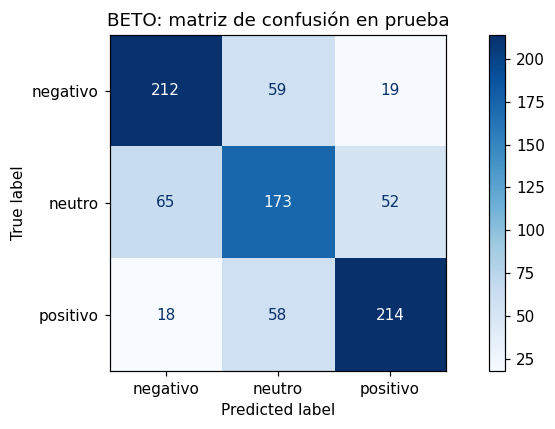

,text,real,prediccion
0,"@user jajajaja dale, hacete la boluda vos jajaja igual a vos nunca se te puede tomar en serio te mando un abrazo desde Perú!",negativo,positivo
1,cada vez que cito un tweet se va la ubicación sin tampoco poder ponerla en el momento a uds les pasa? TE VEO Y ME PICA VICICONTE,neutro,negativo
5,@user ¡Hola Tomás! ¿Habéis visto los nuevos #dinos de #TierraMagna? Es normal que haya colas antes de que comience el espectáculo,positivo,neutro
7,Parce yo estoy igual @user,neutro,negativo
9,"@user quizá para profesionales no sea mucho,pero hay no remunerados principalmente femenino para quienes es un sueño, pasa en mi país",negativo,positivo
10,@user la vemos juntas y lloramos juntas,neutro,negativo
13,"@user @user Uf, los freudianos! Vinieron a tomar café el miércoles y aquí los tengo aún, acampados en el pasillo Bon dia",neutro,negativo
20,"@user pues sí, sé lo que se siente. Pero piénselo como el último esfuerzo, que ya ahorita llegan las vacaciones",positivo,neutro
21,@user @user @user @user HAHAHAHHA MMM NOS VAMOS EN 2 semanas y no tenemos ni hotel Pa la primera noche 😂😂😂,negativo,neutro
24,"No me sorprende que 2ne1 se haya separado, man. Pero aún así me dio en el cora bc es un grupo legendario y empecé mi era kpop con ellas",negativo,positivo


Errores totales: 271 de 870


In [8]:
winner = comparison.iloc[0]
print(f"Learning rate seleccionado: {winner['learning_rate']:.0e}")
print(f"F1 macro de validación: {winner['f1_macro_validacion']:.4f}")

best_model = AutoModelForSequenceClassification.from_pretrained(winner["checkpoint"])
best_dir = ARTIFACTS / "mejor_modelo"
best_model.save_pretrained(best_dir)
tokenizer.save_pretrained(best_dir)

evaluation_trainer = Trainer(
    model=best_model,
    args=TrainingArguments(output_dir=str(ARTIFACTS / "evaluacion"),
                           per_device_eval_batch_size=16, report_to="none", fp16=True),
    processing_class=tokenizer, data_collator=collator, compute_metrics=compute_metrics,
)
prediction = evaluation_trainer.predict(tokenized["test"])
y_true = np.asarray(frames["test"]["label"])
y_pred = prediction.predictions.argmax(axis=-1)
baseline_test = baseline.predict(np.zeros((len(y_true), 1)))
test_scores = pd.DataFrame([
    {"modelo": name, "accuracy": accuracy_score(y_true, pred),
     "f1_macro": f1_score(y_true, pred, labels=[0, 1, 2], average="macro", zero_division=0)}
    for name, pred in [("Referencia constante", baseline_test), ("BETO ajustado", y_pred)]
])
display(test_scores)
test_scores.to_csv(ARTIFACTS / "metricas_prueba.csv", index=False)
report = classification_report(y_true, y_pred, labels=[0, 1, 2],
                               target_names=list(ID2LABEL.values()), output_dict=True, zero_division=0)
display(pd.DataFrame(report).T.round(4))
pd.DataFrame(report).T.to_csv(ARTIFACTS / "reporte_clasificacion.csv")

ConfusionMatrixDisplay.from_predictions(y_true, y_pred, labels=[0, 1, 2],
                                       display_labels=list(ID2LABEL.values()), cmap="Blues")
plt.title("BETO: matriz de confusión en prueba")
plt.tight_layout()
plt.savefig(ARTIFACTS / "matriz_confusion.png")
plt.show()

errors = frames["test"].copy()
errors["real"] = errors["label"].map(ID2LABEL)
errors["prediccion"] = pd.Series(y_pred).map(ID2LABEL)
errors = errors[errors["label"] != y_pred]
with pd.option_context("display.max_colwidth", None):
    display(errors[["text", "real", "prediccion"]].head(10))
print("Errores totales:", len(errors), "de", len(y_true))


## 6. Predicciones sobre textos nuevos

Los siguientes textos son **ejemplos inventados**, no registros del dataset ni una evaluación estadística.
La probabilidad máxima es un puntaje del modelo, no una garantía de acierto ni una confianza calibrada.


In [9]:
new_texts = [
    "Me encantó la atención, resolvieron todo muy rápido.",
    "La reunión está programada para mañana a las tres.",
    "Pésimo servicio, llevo dos horas esperando una respuesta.",
    "Qué maravilla, otra vez se cayó el internet...",
]
device = next(best_model.parameters()).device
inputs = tokenizer(new_texts, padding=True, truncation=True, max_length=MAX_LENGTH, return_tensors="pt").to(device)
best_model.eval()
with torch.no_grad():
    probabilities = best_model(**inputs).logits.softmax(dim=-1).cpu().numpy()
display(pd.DataFrame({
    "texto": new_texts,
    "prediccion": [ID2LABEL[int(i)] for i in probabilities.argmax(axis=-1)],
    "probabilidad_maxima": probabilities.max(axis=-1).round(4),
}))


,texto,prediccion,probabilidad_maxima
0,"Me encantó la atención, resolvieron todo muy r...",positivo,0.9519
1,La reunión está programada para mañana a las t...,neutro,0.8254
2,"Pésimo servicio, llevo dos horas esperando una...",negativo,0.9504
3,"Qué maravilla, otra vez se cayó el internet...",negativo,0.6038


## 7. Resultados y conclusiones

La comparación de las tres tasas de aprendizaje se realiza con F1 macro de validación, manteniendo
las demás condiciones constantes. La evaluación de prueba mide el desempeño de la configuración
seleccionada y lo compara con el clasificador de referencia constante.

El reporte por clase y la matriz de confusión permiten identificar diferencias entre sentimientos.
Los ejemplos de error complementan las métricas agregadas con casos concretos del conjunto de prueba.
El resumen siguiente presenta los valores obtenidos en la ejecución.

### Limitaciones

El conjunto de entrenamiento contiene 1.839 tweets y los experimentos utilizan una sola semilla.
El tamaño de validación limita la estabilidad de la selección. La subjetividad de las etiquetas,
el sarcasmo y la falta de contexto pueden dificultar la clasificación. El desempeño en estos datos
no garantiza el mismo resultado en otras plataformas o variantes regionales.

Los errores de prueba se analizan para informar el resultado. Una nueva versión guiada por esos
errores requeriría una evaluación independiente para medir su generalización.


In [10]:
from IPython.display import Markdown

beto_scores = test_scores.set_index("modelo").loc["BETO ajustado"]
baseline_scores = test_scores.set_index("modelo").loc["Referencia constante"]
display(Markdown(
    f"**Resultado medido:** la configuración seleccionada usó learning rate "
    f"`{winner['learning_rate']:.0e}` y obtuvo F1 macro de validación "
    f"**{winner['f1_macro_validacion']:.4f}**. En los {len(y_true)} tweets de prueba, "
    f"alcanzó accuracy **{beto_scores['accuracy']:.4f}** y F1 macro "
    f"**{beto_scores['f1_macro']:.4f}**. La referencia constante obtuvo F1 macro "
    f"**{baseline_scores['f1_macro']:.4f}**."
))

versions = {package: importlib.metadata.version(package) for package in
            ["torch", "transformers", "datasets", "accelerate", "pandas", "numpy", "scikit-learn"]}
manifest = {
    "dataset": DATASET_ID, "dataset_revision": DATA_REVISION, "subset": "spanish",
    "model": MODEL_ID, "model_revision": MODEL_REVISION,
    "seed": SEED, "max_length": MAX_LENGTH, "learning_rates": LEARNING_RATES,
    "epochs": 3, "batch_size": 8, "gradient_accumulation_steps": 2,
    "weight_decay": 0.01, "warmup_ratio": 0.1,
    "selected_learning_rate": float(winner["learning_rate"]),
    "python": platform.python_version(), "libraries": versions,
    "gpu": torch.cuda.get_device_name(0),
    "sizes": {split: len(df) for split, df in frames.items()},
}
(ARTIFACTS / "configuracion.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")
print("Resultados guardados en:", ARTIFACTS.resolve())


**Resultado medido:** la configuración seleccionada usó learning rate `2e-05` y obtuvo F1 macro de validación **0.6952**. En los 870 tweets de prueba, alcanzó accuracy **0.6885** y F1 macro **0.6886**. La referencia constante obtuvo F1 macro **0.1667**.

Resultados guardados en: /content/resultados_tweets


## Referencias

- Cardiff NLP. [Tweet Sentiment Multilingual: ficha y datos](https://huggingface.co/datasets/cardiffnlp/tweet_sentiment_multilingual).
- Barbieri, F., Espinosa-Anke, L. y Camacho-Collados, J. (2022). [XLM-T: Multilingual Language Models in Twitter for Sentiment Analysis and Beyond](https://aclanthology.org/2022.lrec-1.27/).
- Cañete y colaboradores. [BETO: Spanish BERT](https://huggingface.co/dccuchile/bert-base-spanish-wwm-cased).
- Hugging Face. [Trainer, versión 4.57.1](https://huggingface.co/docs/transformers/v4.57.1/en/main_classes/trainer).

Las versiones fijadas buscan reproducibilidad; no implican que sean las versiones más recientes.
